<a href="https://colab.research.google.com/github/nasy-sr/artificial-intelligence-coursework-2024-genap/blob/main/04_multi_class_text_classification_spacy_tokenizer_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(style='darkgrid', font_scale=1.6)
import spacy
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.naive_bayes import MultinomialNB

In [ ]:
#Mont Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Path ke file csv
file_path = '/content/drive/MyDrive/Colab Notebooks/AI_Class/20_newsgroup.csv'

In [ ]:
# Cell 2: Load Dataset

#Read CSV File
df=pd.read_csv(file_path, encoding='latin-1')

#Drop rows with missing text and assign the result back to df
df = df.dropna(subset=['text']).reset_index(drop=True)

#Show shape and preview
print("Dataset size:", df.shape)
df.head()

Dataset size: (11096, 5)


,Unnamed: 0,text,target,title,date
0,0,I was wondering if anyone out there could enli...,7,rec.autos,2025-05-07 02:05:02.154073
1,17,I recently posted an article asking what kind ...,7,rec.autos,2025-05-07 02:05:02.154073
2,29,\nIt depends on your priorities. A lot of peo...,7,rec.autos,2025-05-07 02:05:02.154073
3,56,an excellent automatic can be found in the sub...,7,rec.autos,2025-05-07 02:05:02.154073
4,64,: Ford and his automobile. I need information...,7,rec.autos,2025-05-07 02:05:02.154073


In [ ]:
# Cell 3: Explore Label/Kelas

print("Unique labels:", df['title'].unique())
print("\nLabel Encoding (target):", df['target'].unique())
print("nExample Article:\n", df['text'][0])

Unique labels: ['rec.autos' 'comp.sys.mac.hardware' 'comp.graphics' 'sci.space'
 'talk.politics.guns' 'sci.med' 'comp.sys.ibm.pc.hardware'
 'comp.os.ms-windows.misc' 'rec.motorcycles' 'talk.religion.misc'
 'misc.forsale' 'alt.atheism' 'sci.electronics' 'comp.windows.x'
 'rec.sport.hockey' 'rec.sport.baseball' 'soc.religion.christian'
 'talk.politics.mideast' 'talk.politics.misc' 'sci.crypt']

Label Encoding (target): [ 7  4  1 14 16 13  3  2  8 19  6  0 12  5 10  9 15 17 18 11]
nExample Article:
 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


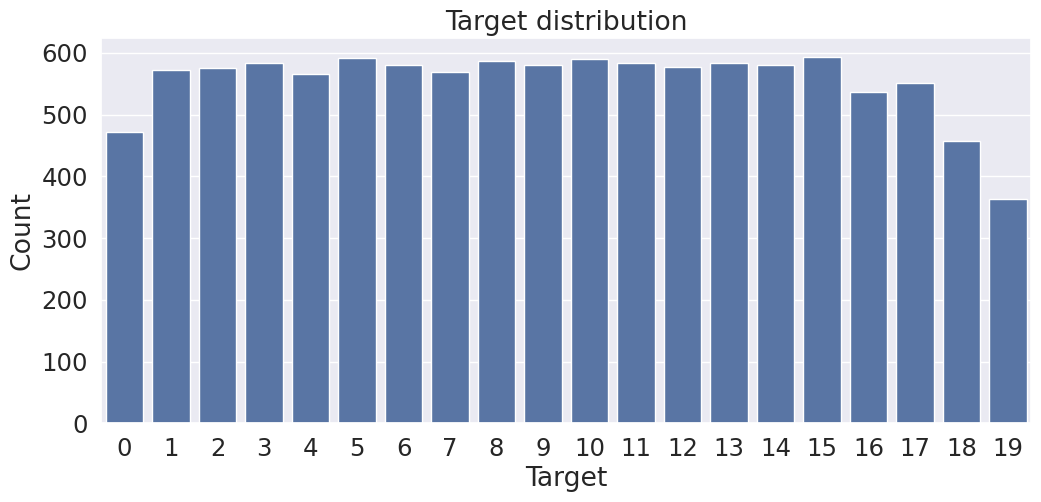

In [ ]:
# Cell 4: Visualisasi distribusi target (Label/Kelas)

plt.figure(figsize=(12, 5))
sns.countplot(x=df['target'])
plt.title('Target distribution')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

In [ ]:
# Cell 5: Custom Tokenizer Menggunakan Library spacy

nlp = spacy.blank('en')

def custom_tokenizer(doc):
    return [t.text for t in nlp(doc) if not t.is_punct and not t.is_space and t.is_alpha]

In [ ]:
# Cell 6: Train-Test Split (40% sebagai testing)

X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['target'], test_size=0.4, random_state=42, stratify=df['target']
    )

# Drop any potential NaN values from the training and testing sets
X_train = X_train.dropna()
X_test = X_test.dropna()

In [ ]:
%%time
# Cell 7: Vectorisasi Data Teks

vectorizer = CountVectorizer(tokenizer=custom_tokenizer)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CPU times: user 26.6 s, sys: 178 ms, total: 26.8 s
Wall time: 27.1 s


In [ ]:
%%time
# Cell 8: Train Naive Bayes Classifier

clf = MultinomialNB()
clf.fit(X_train_vec, y_train)

CPU times: user 61.2 ms, sys: 16.9 ms, total: 78.1 ms
Wall time: 81.1 ms


MultinomialNB()

In [ ]:
# cell 9: Prediksi and Evaluasi

y_pred = clf.predict(X_test_vec)
print("F1 Score (macro):", f1_score(y_test, y_pred, average='macro'))

F1 Score (macro): 0.5820069345187242


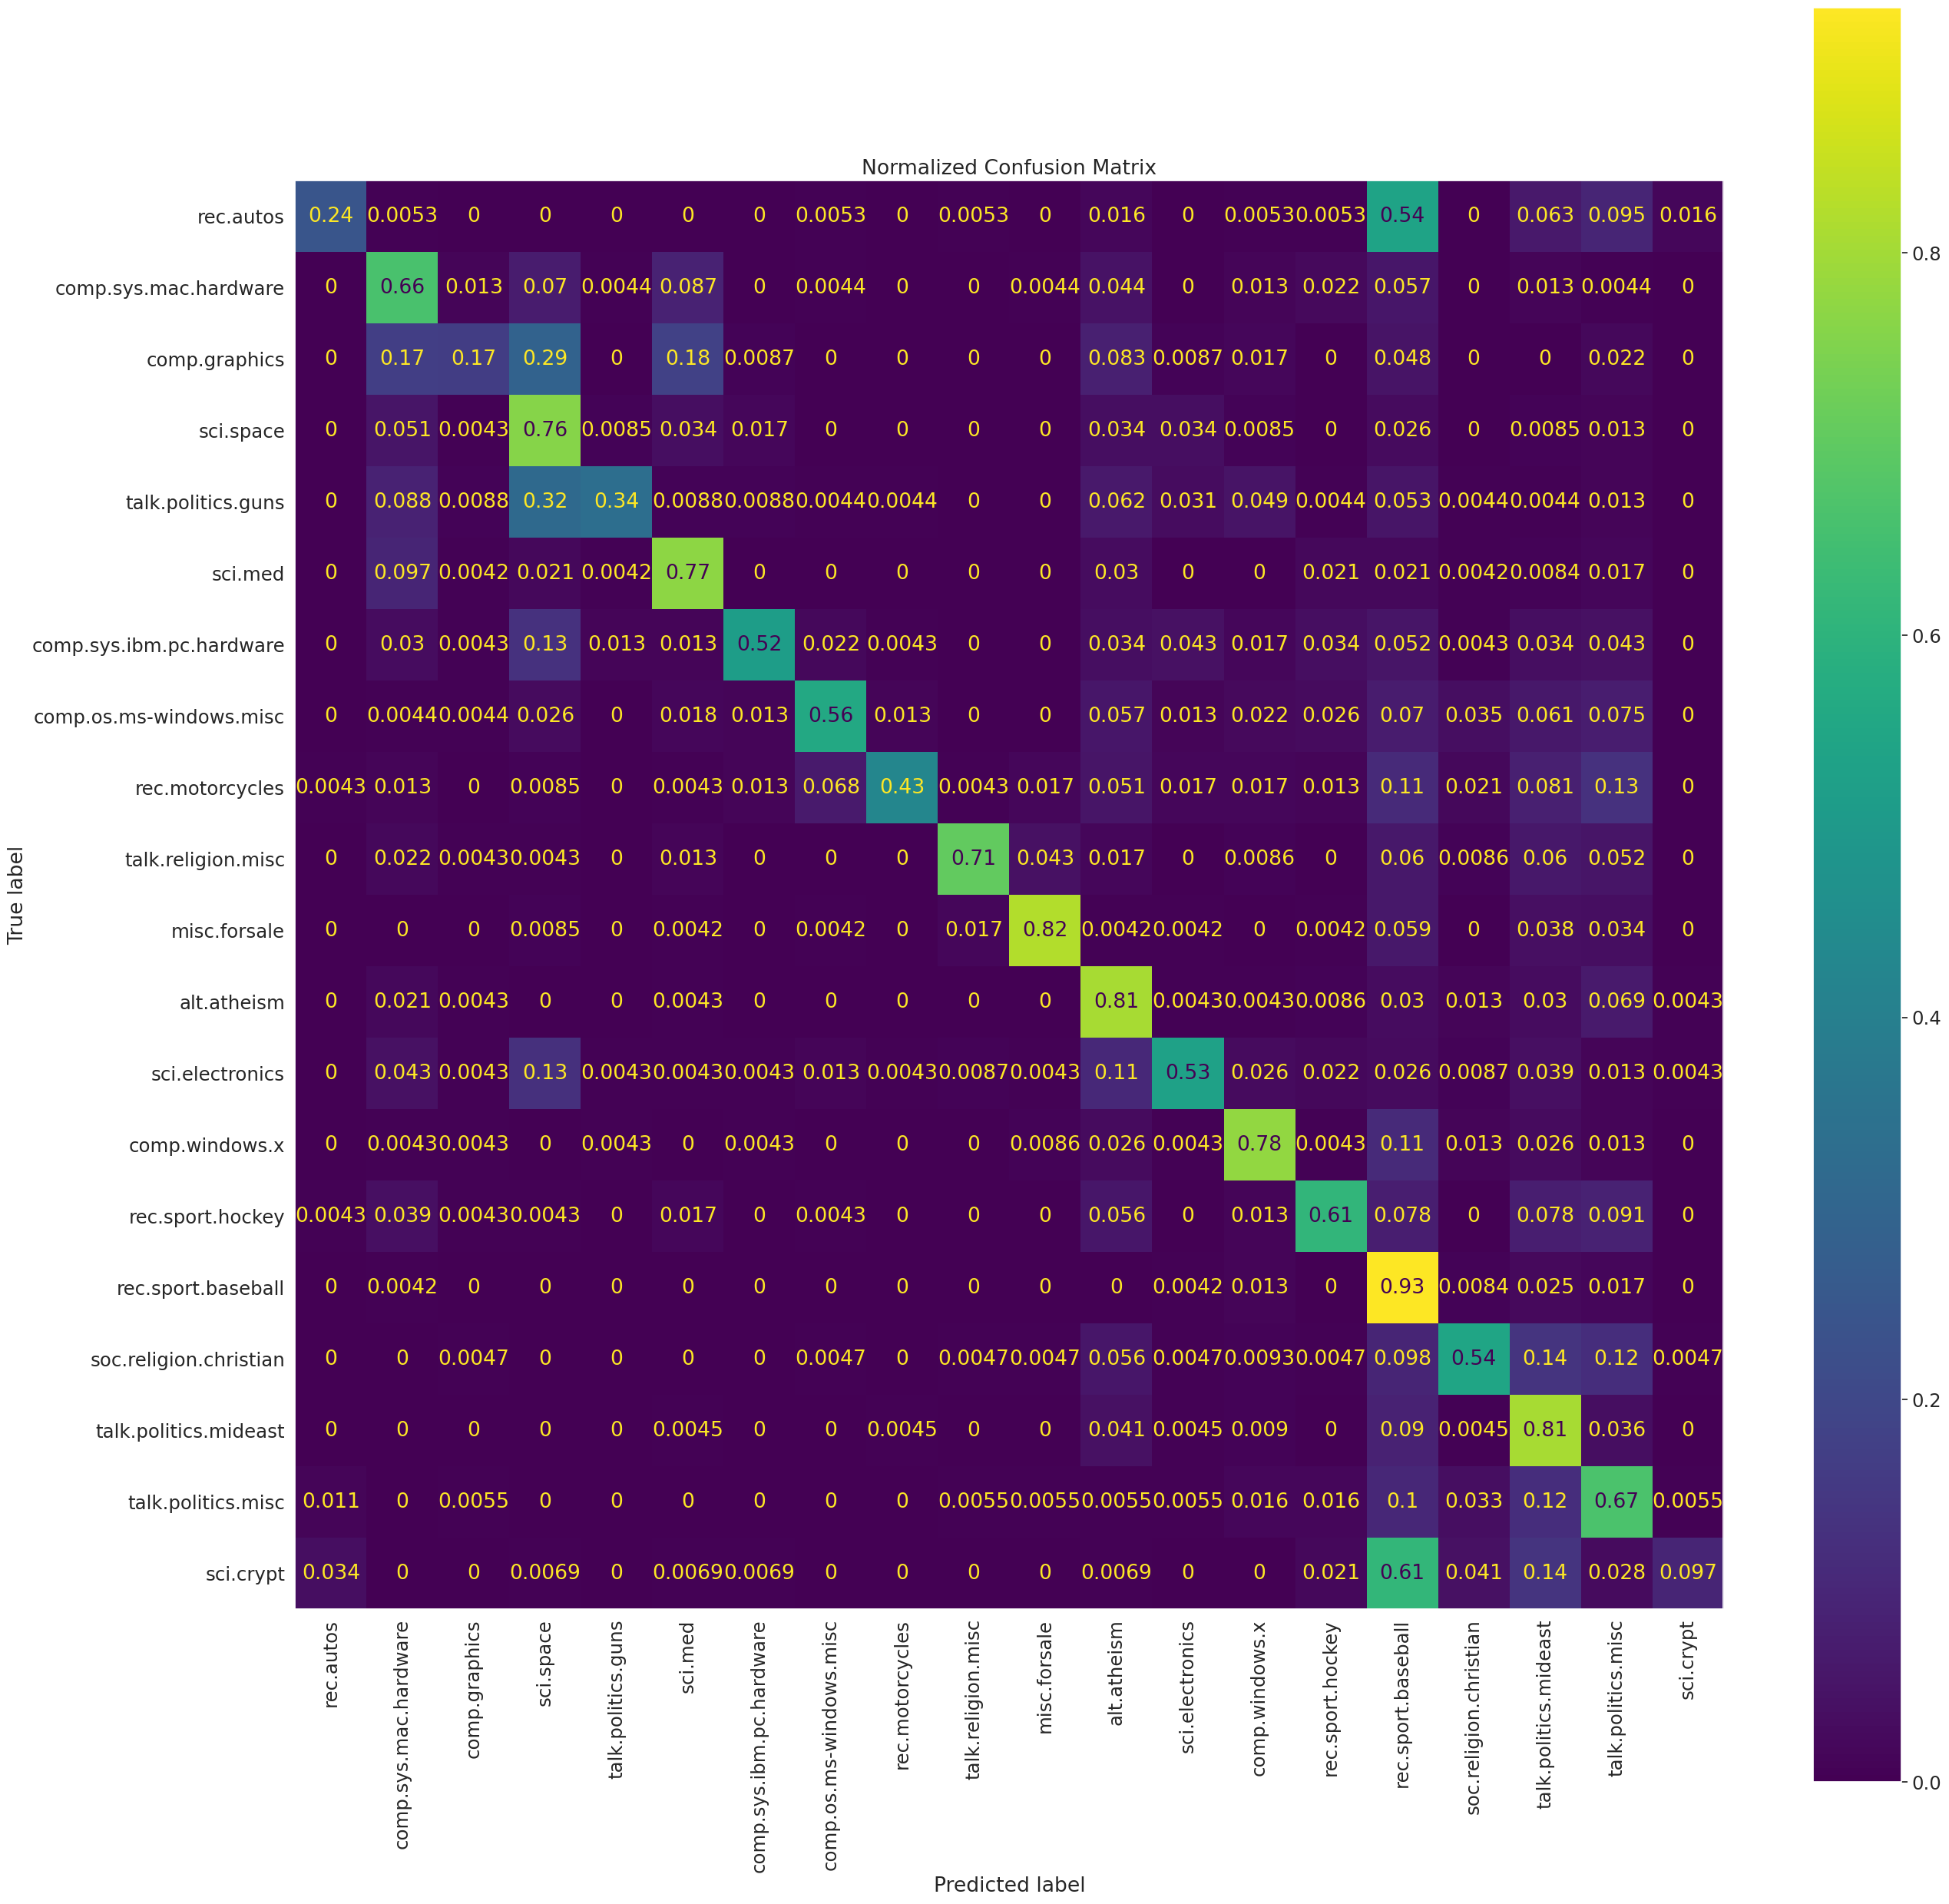

In [ ]:
# Cell 10: Confusion matrix

fig, ax = plt.subplots(figsize=(30,30))
ax.grid(False)

# Corrected the typo from ConfusionMathrixDisplay to ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
     clf, X_test_vec, y_test, normalize='true',
    display_labels=df['title'].unique(), xticks_rotation='vertical', ax=ax
)
plt.title("Normalized Confusion Matrix")
plt.show()

In [ ]:
#Cell 11: Classification Report

print(classification_report(y_test, y_pred, target_names=df['title'].unique()))

                          precision    recall  f1-score   support

               rec.autos       0.84      0.24      0.38       189
   comp.sys.mac.hardware       0.52      0.66      0.59       229
           comp.graphics       0.71      0.17      0.27       230
               sci.space       0.43      0.76      0.55       234
      talk.politics.guns       0.89      0.34      0.49       226
                 sci.med       0.67      0.77      0.72       237
comp.sys.ibm.pc.hardware       0.88      0.52      0.65       232
 comp.os.ms-windows.misc       0.81      0.56      0.66       228
         rec.motorcycles       0.93      0.43      0.58       235
      talk.religion.misc       0.94      0.71      0.81       232
            misc.forsale       0.91      0.82      0.86       236
             alt.atheism       0.53      0.81      0.64       233
         sci.electronics       0.75      0.53      0.62       231
          comp.windows.x       0.76      0.78      0.77       233
        r

In [ ]:
#Memuat model bahasa Inggris Lengkap dari spacy
#Model ini mencakup kemampuan seperti tokenisasi, Lemmatisasi, POS tagging, NER, dll
#Memuat model bahasa Inggris Lengkap dari spacy

# Install the spaCy large English model
!python -m spacy download en_core_web_lg

nlp = spacy.load('en_core_web_lg')

# Menentukan komponen pipeline NLP yang ingin dinonaktifkan untuk efisiensi waktu
# 'ner' Named Entity Recognition, 'parser' = dependency parser
unwanted_pipes = ['ner', 'parser']

# Mendefinisikan tokenizer kustom menggunakan spaCy
def custom_tokenizer(doc):
  # Menonaktifkan sementara komponen pipeline yang tidak dibutuhkan
  with nlp.disable_pipes(*unwanted_pipes):
    return [
        t.lemma_ # Mengambil bentuk dasar (Lemma) dari setiap token
        for t in nlp(doc)
        if not t.is_punct
        and not t.is_space
        and not t.is_stop
        and t.is_alpha
    ]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 3.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
